In [1]:
%matplotlib widget
import importlib
import numpy as np
import scipy as sc
from scipy.special import jv
import os
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
import mpmath
from mpmath import *
import time
import pandas as pd
import matplotlib
import matplotlib.image
import matplotlib.lines as mlines
import matplotlib.patches as mpatches

os.chdir(r'C:\Users\nberr\ENS_Lyon\Thèse\Code\AR_estimation\New_code')
from AR_interpolation_func_VF import *
import AR_interpolation_func_VF
importlib.reload(AR_interpolation_func_VF)
from AR_interpolation_func_VF  import *

os.chdir(r'C:\Users\nberr\ENS_Lyon\Thèse\Code\AR_estimation\New_code')
from AR_interpolations_plotting_VF import *
import AR_interpolations_plotting_VF
importlib.reload(AR_interpolations_plotting_VF)
from AR_interpolations_plotting_VF  import *


fontsize=30
import matplotlib as mpl
mpl.rcParams["font.size"] = 18

## Get Treated Data

In [2]:
path = r'H:\commun\Experiments (from 2018)\Nanoscope 2\Projects\ULTRASINGLE\Measurements\AuND_specific_AR_Marguet'

Simu_Data = {}
Simu_SPR_data = {}
Exp_Data = {}
Colors_dic = {}
Points = {}

# Sapphire result
key_1 = 'Sapphire'

Simu_Data[key_1] = {}

sample_name_1 = r'\Sapphire'
root_simu_1 = path + sample_name_1 + r'\AR_estimation\SPR_simu_treated'
fname_data_simu_1 = 'Treated_simulations'
Simu_SPR_data[key_1], Simu_Data[key_1]['Lda_RBF'], Simu_Data[key_1]['E_RBF'], Simu_Data[key_1]['W_RBF'], Simu_Data[key_1]['Aire_RBF'], Points[key_1] = get_simu_data_and_interpolate(root_simu_1, fname_data_simu_1, kernel='linear')

root_exp_1 = path + sample_name_1 + r'\AR_estimation\ND_measurements_AR_treated'

fname_data_exp_1 = 'Treated_data'
Exp_Data[key_1] = get_treated_AR_data(root_exp_1, fname_data_exp_1)

Colors_dic[key_1] = {}
Colors_dic[key_1]['main'] = "#1A1AFF"

# Silice - thick results
key_2 = 'Sapphire - forme de bouée'

Simu_Data[key_2] = {}


root_simu_2 = r'H:\commun\Utilisateur FNO\Nathan\COMSOL\AuND\SPR\Sapphire\SPR - round shape\Ar_interpolation'
fname_data_simu_2 = 'Treated_simulations'
Simu_SPR_data[key_2], Simu_Data[key_2]['Lda_RBF'], Simu_Data[key_2]['E_RBF'], Simu_Data[key_2]['W_RBF'], Simu_Data[key_2]['Aire_RBF'], Points[key_2] = get_simu_data_and_interpolate(root_simu_2, fname_data_simu_2, kernel='linear')

root_exp_2 = r'H:\commun\Utilisateur FNO\Nathan\COMSOL\AuND\SPR\Sapphire\SPR - round shape\Ar_interpolation'
fname_data_exp_2 = 'Treated_data'
Exp_Data[key_2] = get_treated_AR_data(root_exp_2, fname_data_exp_2)

Colors_dic[key_2] = {}
Colors_dic[key_2]['main'] = 'black'




# Silice - thick results
key_3 = 'Sapphire - r = 7 nm'

Simu_Data[key_3] = {}


root_simu_3 = r'H:\commun\Utilisateur FNO\Nathan\COMSOL\AuND\SPR\Sapphire\SPR - Intermdiate shape\size_sweep_r_7nm\Treated_SPR'
fname_data_simu_3 = 'Treated_simulations'
Simu_SPR_data[key_3], Simu_Data[key_3]['Lda_RBF'], Simu_Data[key_3]['E_RBF'], Simu_Data[key_3]['W_RBF'], Simu_Data[key_3]['Aire_RBF'], Points[key_3] = get_simu_data_and_interpolate(root_simu_3, fname_data_simu_3, kernel='linear')

root_exp_3 = r'H:\commun\Utilisateur FNO\Nathan\COMSOL\AuND\SPR\Sapphire\SPR - Intermdiate shape\size_sweep_r_7nm\Treated_SPR'
fname_data_exp_3 = 'Treated_data'
Exp_Data[key_3] = get_treated_AR_data(root_exp_3, fname_data_exp_3)

Colors_dic[key_3] = {}
Colors_dic[key_3]['main'] = "#00872D"




# Silice - thick results
key_4 = 'Sapphire - round corner'

Simu_Data[key_4] = {}


root_simu_4 = r'H:\commun\Utilisateur FNO\Nathan\COMSOL\AuND\SPR\Sapphire\SPR - Intermdiate shape\size_sweep_half_curved\Treated_SPR'
fname_data_simu_4 = 'Treated_simulations'
Simu_SPR_data[key_4], Simu_Data[key_4]['Lda_RBF'], Simu_Data[key_4]['E_RBF'], Simu_Data[key_4]['W_RBF'], Simu_Data[key_4]['Aire_RBF'], Points[key_4] = get_simu_data_and_interpolate(root_simu_4, fname_data_simu_4, kernel='linear')

root_exp_4 = r'H:\commun\Utilisateur FNO\Nathan\COMSOL\AuND\SPR\Sapphire\SPR - Intermdiate shape\size_sweep_half_curved\Treated_SPR'
fname_data_exp_4 = 'Treated_data'
Exp_Data[key_4] = get_treated_AR_data(root_exp_4, fname_data_exp_4)

Colors_dic[key_4] = {}
Colors_dic[key_4]['main'] = "#870000"



Error : there is no treated data


TypeError: 'NoneType' object is not iterable

## Key in my dictionnaries

ND dictionnary useful keys :

ND['1D']['D', 'h', 'AR']

ND['2D']['D', 'h', 'AR']

  


## Find closets point

In [ ]:
h, D = 30, 71
compt = 0
for key in Simu_Data :

    print('-----------------------------------------------')
    print(key)
    
    simu = Simu_Data[key]
    if compt == 0 :
            
        for kkey in simu :
            print(kkey)

            ccompt = 0
        for kkkey in Exp_Data[key] :
            if ccompt==0 :

                print([str(x) for x in Exp_Data[key][kkkey]] )
            ccompt +=1
    #compt +=1

-----------------------------------------------
Sapphire
Lda_RBF
E_RBF
W_RBF
Aire_RBF
['ND_name', 'AR', 'zone', 'name', 'date', 'lda_SPR', 'E_SPR', 'w_SPR', 'Aire_SPR', 'D_estimated 2D', 'h_estimated 2D', 'Gsurf_estimated 2D', 'AR_estimated_2D', 'D_est_1D', 'AR_est_aire', 'Gamma_surf_est_aire', 'lambda_probe', 'polar', 'tau', 'tau_err', 'T', 'T_err', 'phi', 'phi_err', 'f', 'f_red_2D_est', 'f_red_1D_est', 'Q', 'Q_err', 'tau2', 'tau2_err', 'T2', 'T2_err', 'phi2', 'phi2_err', 'Q2', 'Q2_err', 'Comment', 'f2', '1D', '2D']
-----------------------------------------------
Sapphire - forme de bouée
Lda_RBF
E_RBF
W_RBF
Aire_RBF
['ND_name', 'AR', 'zone', 'name', 'date', 'lda_SPR', 'E_SPR', 'w_SPR', 'Aire_SPR', 'D_estimated 2D', 'h_estimated 2D', 'Gsurf_estimated 2D', 'AR_estimated_2D', 'D_est_1D', 'AR_est_aire', 'Gamma_surf_est_aire', 'lambda_probe', 'polar', 'tau', 'tau_err', 'T', 'T_err', 'phi', 'phi_err', 'f', 'f_red_2D_est', 'f_red_1D_est', 'Q', 'Q_err', 'tau2', 'tau2_err', 'T2', 'T2_err', 'p

## Plot the 2D convergene

Sapphire
Sapphire - forme de bouée
Sapphire - r = 7 nm
Sapphire - round corner


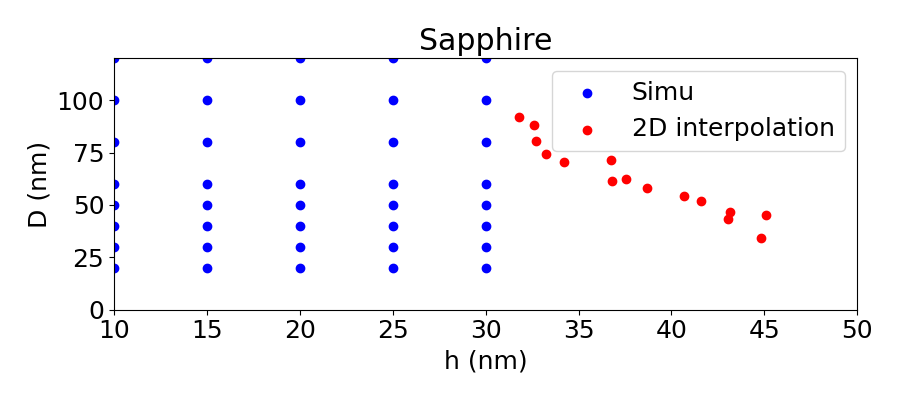

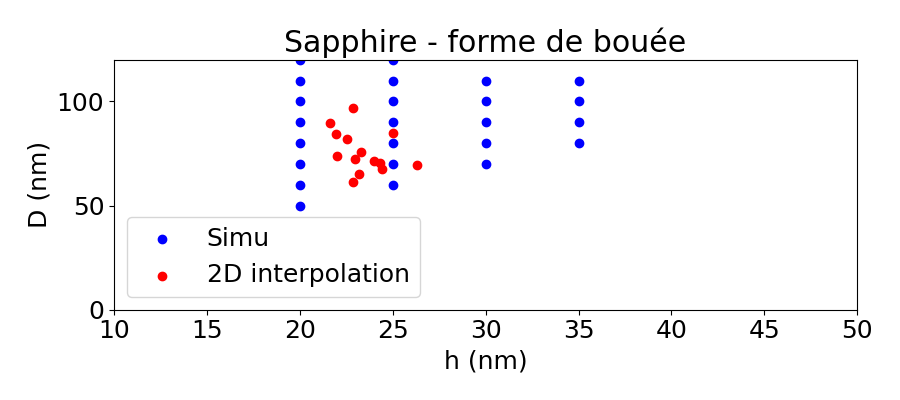

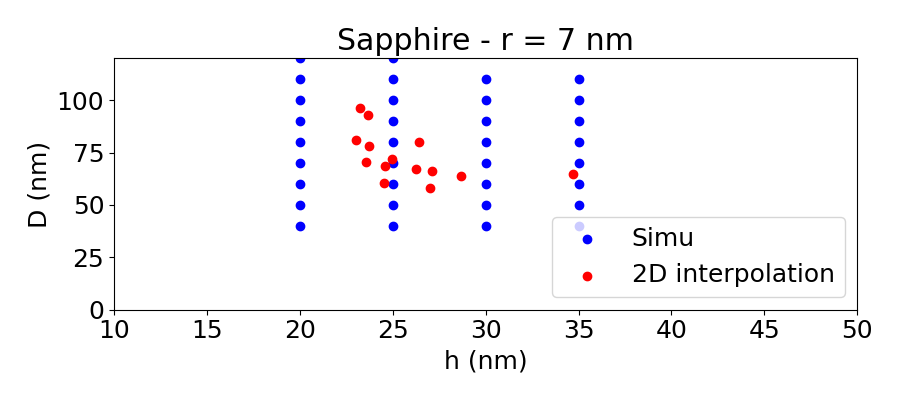

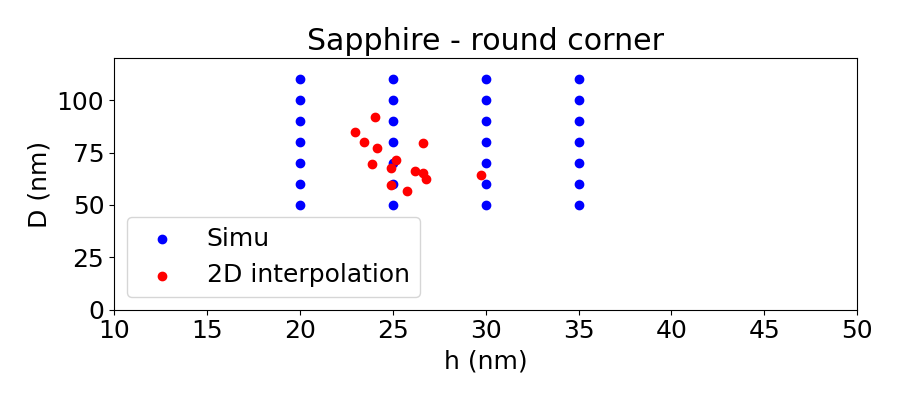

In [ ]:
for key in Simu_SPR_data :
    print(key)
    simu_data = Simu_SPR_data[key]
    exp_data = Exp_Data[key]
    points = Points[key]
    fig, ax = plt.subplots(figsize = (9,4))


    ax.set_xlabel('h (nm)')
    ax.set_ylabel('D (nm)')
    ax.set_title(key)

    plt.scatter(points[:,0], points[:,1], color='blue', label = 'Simu')
    plt.scatter([exp_data[kkey]['2D']['h'] for kkey in exp_data], [exp_data[kkey]['2D']['D'] for kkey in exp_data], color='red', label = '2D interpolation')

    ax.set_ylim((0, 120))
    ax.set_xlim(10, 50)
    plt.legend()
    plt.tight_layout()




C:\Users\nberr\ENS_Lyon\Thèse\Code\AR_estimation\New_code\AR_interpolations_plotting_VF.py:46: RuntimeWarning: divide by zero encountered in divide
  cs = ax.contour(H, D, DD/HH, levels=[ 2.3], colors='black', alpha=0.6)
C:\Users\nberr\ENS_Lyon\Thèse\Code\AR_estimation\New_code\AR_interpolations_plotting_VF.py:46: RuntimeWarning: invalid value encountered in divide
  cs = ax.contour(H, D, DD/HH, levels=[ 2.3], colors='black', alpha=0.6)


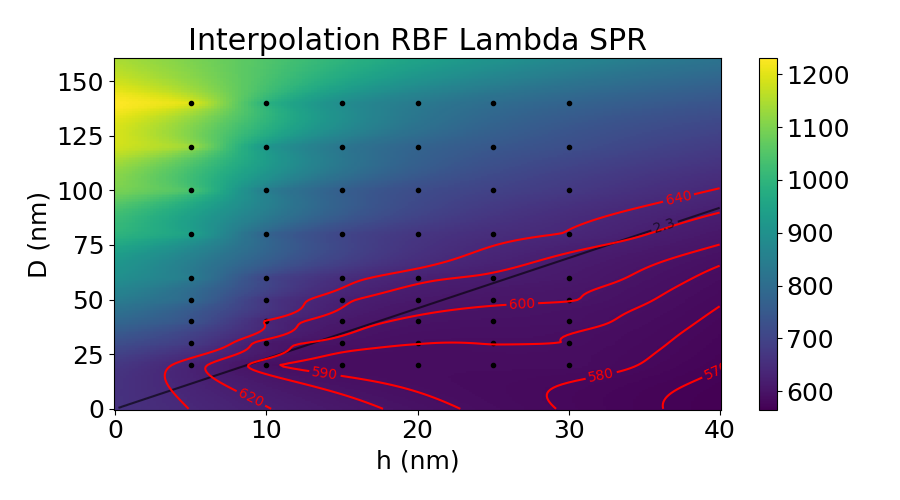

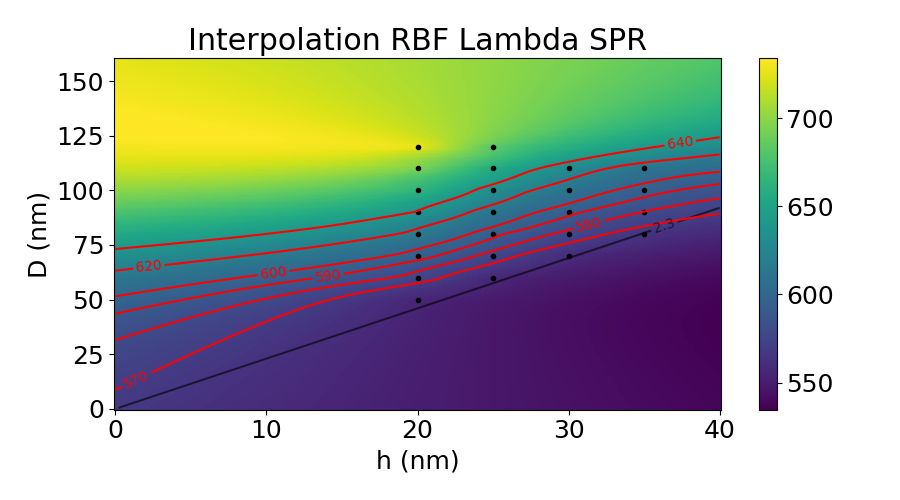

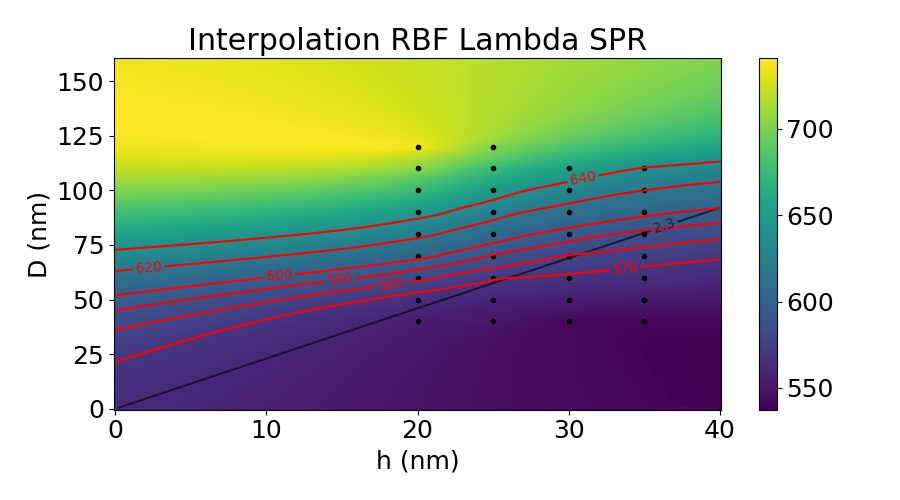

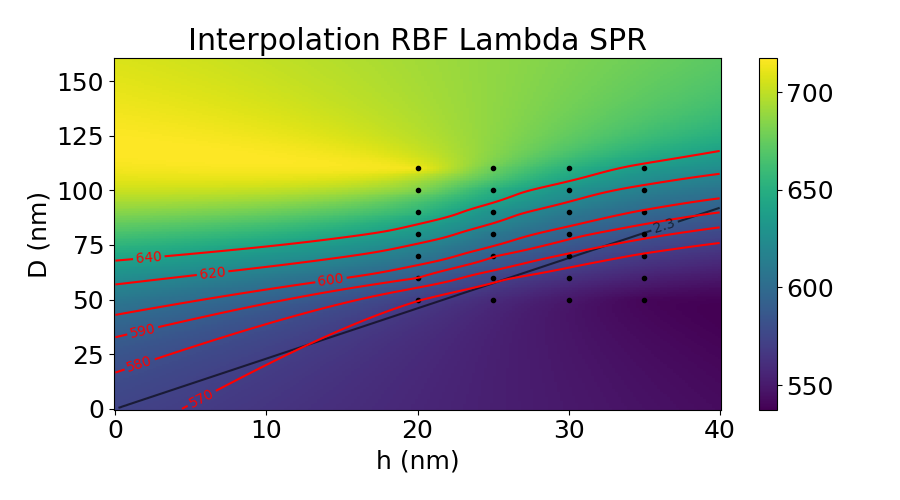

In [ ]:
H_lisse = np.linspace(0, 40, 200)
D_lisse = np.linspace(0, 160, 200)
HH_lisse, DD_lisse = np.meshgrid( H_lisse, D_lisse)
points_lisses = np.array(list(zip(HH_lisse.flatten(), DD_lisse.flatten())))


for key in Simu_Data :
    simu = Simu_Data[key]
    points = Points[key]
    plot_func_interp(simu['Lda_RBF'], H_lisse, D_lisse, HH_lisse, DD_lisse, points_lisses, points, title='Lambda SPR', contour_specif=[570, 580, 590,  600, 620, 640])


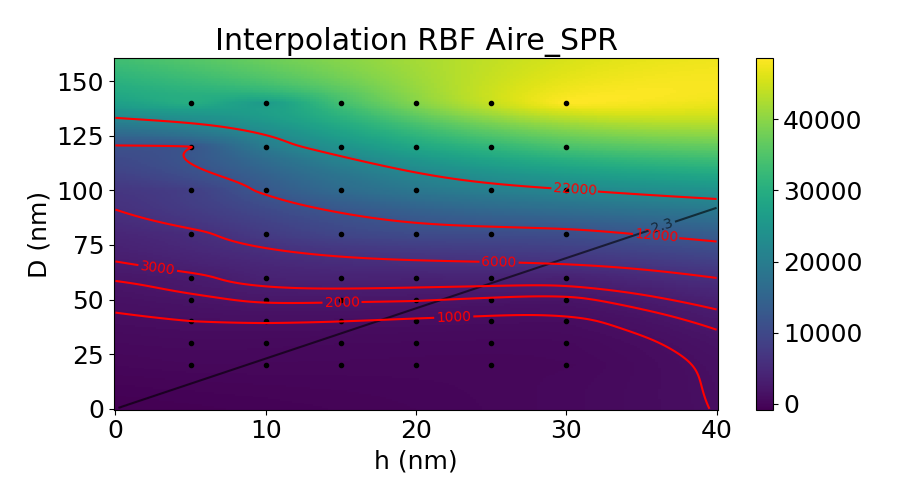

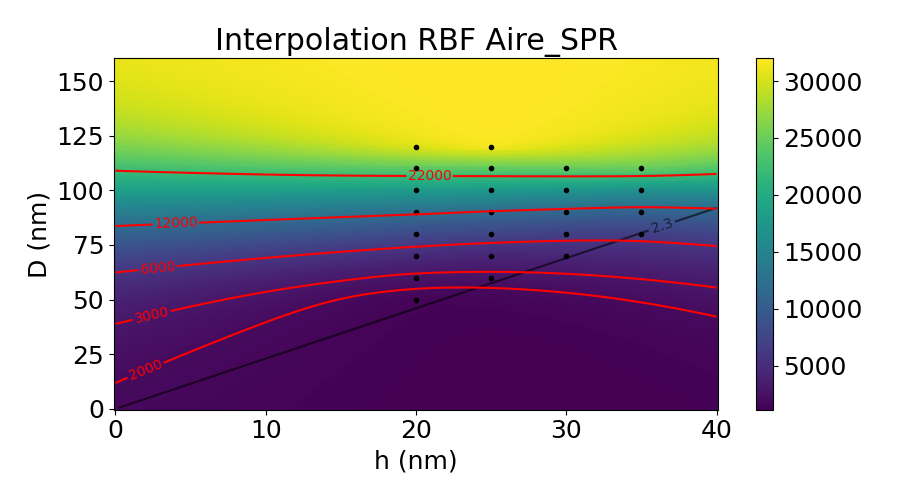

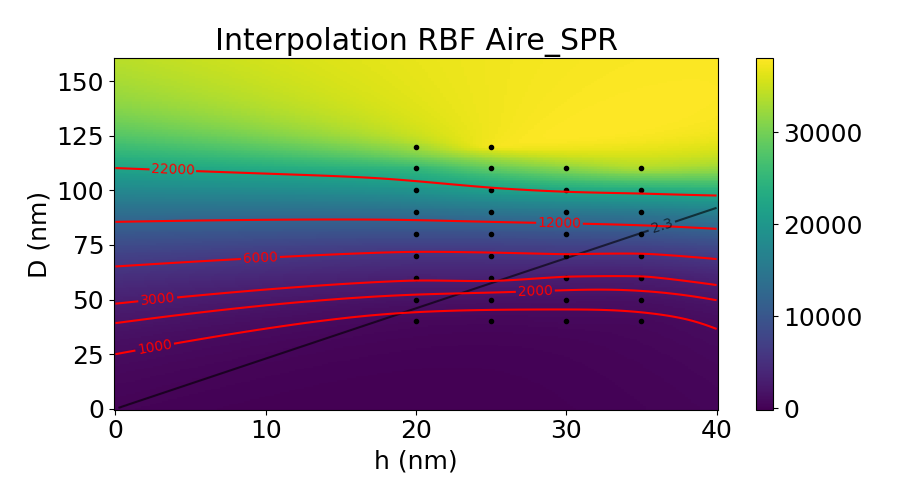

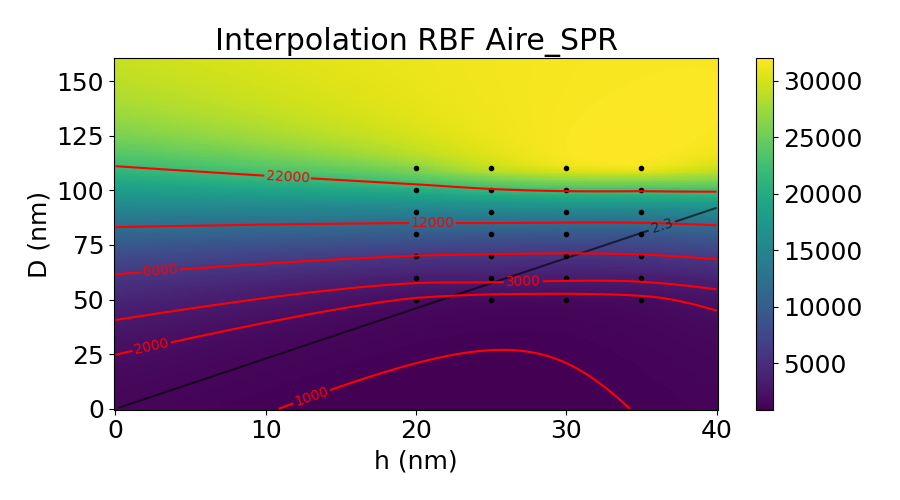

In [ ]:
H_lisse = np.linspace(0, 40, 200)
D_lisse = np.linspace(0, 160, 200)
HH_lisse, DD_lisse = np.meshgrid( H_lisse, D_lisse)
points_lisses = np.array(list(zip(HH_lisse.flatten(), DD_lisse.flatten())))


for key in Simu_Data :
    simu = Simu_Data[key]
    points = Points[key]
    plot_func_interp(simu['Aire_RBF'], H_lisse, D_lisse, HH_lisse, DD_lisse, points_lisses, points, title='Aire_SPR', contour_specif=[1000, 2000, 3000,6000, 12000,22000])

## Plot reduced frequencies

## Show experimental fit of spectra, and the spectra corresponding of fitted AR

In [ ]:
show_closest_fit = 0
show_exact_fit = 0

tested_sample = 'Sapphire'

In [ ]:
if show_closest_fit :

    simu = Simu_SPR_data[tested_sample]
    exp_data = Exp_Data[tested_sample]
    points = Points[tested_sample]

    E = np.linspace(1.5, 3, 1000)

    for key in exp_data :
        
        ND = exp_data[key]

        

        fig, ax = plt.subplots(figsize=(9,4))
        plt.title(key)
        ax.plot(E, Lorentz_no_offset(E, ND['E_SPR'], ND['w_SPR']*1e-3, ND['Aire_SPR']), color='black', label = 'exp spectra')

        # Get the closest simulated spectra for the extracted geometry.

        # idx_2D = np.argmin(np.linalg.norm(np.array(simu['points']-[ND['h_estimated 2D'], ND['D_estimated 2D']]), axis=1))
        # ax.plot(E, Lorentz_no_offset(E, simu['E_SPR'][idx_2D], simu['W'][idx_2D], simu['Aire_SPR'][idx_2D]), color='blue', label = '2D : h = {:.1f}, D = {:.1f}'.format(simu['points'][idx_2D][0],simu['points'][idx_2D][1] ))
        
        # idx_1D_21nm = np.argmin(np.linalg.norm(np.array(simu['points']-[21, ND['D_est_1D']]), axis=1))
        # ax.plot(E, Lorentz_no_offset(E, simu['E_SPR'][idx_1D_21nm], simu['W'][idx_1D_21nm], simu['Aire_SPR'][idx_1D_21nm]), color='red', label = '2D : h = 21 nm, D = {:.1f}'.format(simu['points'][idx_1D_21nm][1]))
        
        # idx_1D_25nm = np.argmin(np.linalg.norm(np.array(simu['points']-[25, ND['D_est_1D']]), axis=1))
        # ax.plot(E, Lorentz_no_offset(E, simu['E_SPR'][idx_1D_25nm], simu['W'][idx_1D_25nm], simu['Aire_SPR'][idx_1D_25nm]), color='orange', label = '2D : h = 25 nm, D = {:.1f}'.format(simu['points'][idx_1D_25nm][1]))   
        


        # Prend la largeur expérimentale de la résonance, et le spectre simulé le plus proche (seulement à partir des spectres simulés)
        idx_2D = np.argmin(np.linalg.norm(np.array(points-[ND['2D']['h'], ND['2D']['D']]), axis=1))
        ax.plot(E, Lorentz_no_offset(E, simu['E_SPR'][idx_2D], ND['w_SPR']*1e-3, simu['Aire_SPR'][idx_2D]), color='blue', label = '2D : h = {:.1f} nm, D = {:.1f} nm / plot ({}, {})'.format(ND['2D']['h'], ND['2D']['D'], simu['points'][idx_2D][0],simu['points'][idx_2D][1] ))
        
        idx_1D_21nm = np.argmin(np.linalg.norm(np.array(points-[21, ND['1D']['D']]), axis=1))
        ax.plot(E, Lorentz_no_offset(E, simu['E_SPR'][idx_1D_21nm], ND['w_SPR']*1e-3, simu['Aire_SPR'][idx_1D_21nm]), color='red', label = '1D : h = 21 nm, D = {:.1f} nm / plot({}, {})'.format(ND['1D']['D'], simu['points'][idx_1D_21nm][0], simu['points'][idx_1D_21nm][1]))
        
        idx_1D_25nm = np.argmin(np.linalg.norm(np.array(points-[25, ND['1D']['D']]), axis=1))
        ax.plot(E, Lorentz_no_offset(E, simu['E_SPR'][idx_1D_25nm], ND['w_SPR']*1e-3, simu['Aire_SPR'][idx_1D_25nm]), color='orange', label = '1D : h = 25 nm, D = {:.1f} nm / plot({}, {})'.format(ND['1D']['D'], simu['points'][idx_1D_25nm][0], simu['points'][idx_1D_25nm][1]))   
        

        idx_1D_35nm = np.argmin(np.linalg.norm(np.array(points-[35, ND['1D']['D']]), axis=1))
        ax.plot(E, Lorentz_no_offset(E, simu['E_SPR'][idx_1D_35nm], ND['w_SPR']*1e-3, simu['Aire_SPR'][idx_1D_35nm]), color='green', label = '1D : h = 35 nm, D = {:.1f} nm / plot({}, {})'.format(ND['1D']['D'], simu['points'][idx_1D_35nm][0], simu['points'][idx_1D_35nm][1]))   
        
        





        ax.legend(fontsize =10)

        ax.set_ylim(top = Lorentz_no_offset(E, ND['E_SPR'], ND['w_SPR']*1e-3, ND['Aire_SPR']).max()*1.3)
        ax.set_xlim((1.5, 3.3))

In [ ]:
if show_exact_fit :

    simu = Simu_Data[tested_sample]
    exp_data = Exp_Data[tested_sample]
    points = Points[tested_sample]

    E = np.linspace(1.5, 3, 1000)

    for key in exp_data :
        
        ND = exp_data[key]

        

        fig, ax = plt.subplots(figsize=(9,4))
        plt.title(key)
        
        point_2D = [[ND['2D']['h'], ND['2D']['D']]]
        point_1D_21nm = [[21, ND['1D']['D']]]
        point_1D_25nm = [[25, ND['1D']['D']]]
        point_1D_30nm = [[30, ND['1D']['D']]]
        
        ax.plot(E, Lorentz_no_offset(E, simu['E_RBF'](point_2D), ND['w_SPR']*1e-3, simu['Aire_RBF'](point_2D)), color='blue', label = '2D : h = {:.1f} nm, D = {:.1f} nm '.format(ND['2D']['h'], ND['2D']['D'], ))
        

        ax.plot(E, Lorentz_no_offset(E, simu['E_RBF'](point_1D_21nm), ND['w_SPR']*1e-3, simu['Aire_RBF'](point_1D_21nm)), color='red', label = '1D : h = 21 nm, D = {:.1f} nm'.format(ND['1D']['D'] ))
        ax.plot(E, Lorentz_no_offset(E, simu['E_RBF'](point_1D_25nm), ND['w_SPR']*1e-3, simu['Aire_RBF'](point_1D_25nm)), color='orange', label = '1D : h = 25 nm, D = {:.1f} nm'.format(ND['1D']['D'] ))
        ax.plot(E, Lorentz_no_offset(E, simu['E_RBF'](point_1D_30nm), ND['w_SPR']*1e-3, simu['Aire_RBF'](point_1D_30nm)), color='green', label = '1D : h = 30 nm, D = {:.1f} nm'.format(ND['1D']['D'] ))

        # ax.plot(E, Lorentz_no_offset(E, simu['E_SPR'][idx_1D_35nm], ND['w_SPR']*1e-3, simu['Aire_SPR'][idx_1D_35nm]), color='green', label = '1D : h = 25 nm, D = {:.1f} nm'.format(ND['D_est_1D']))   
        ax.plot(E, Lorentz_no_offset(E, ND['E_SPR'], ND['w_SPR']*1e-3, ND['Aire_SPR']),linestyle = '--', color='black', label = 'exp spectra')

        





        ax.legend(fontsize =10)

        ax.set_ylim(top = Lorentz_no_offset(E, ND['E_SPR'], ND['w_SPR']*1e-3, ND['Aire_SPR']).max()*1.3)